# Прогнозирование продаж: анализ и предобработка временного ряда

**Товар:** 85099B JUMBO BAG RED RETROSPOT (большая сумка-шоппер). Товар 85123A, разобранный на занятии, исключён.
**Показатель:** число проданных штук (`Quantity`) по фактическим продажам, без отмен и возвратов.
**Данные:** [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), транзакции британского онлайн-магазина подарков за 01.12.2010–09.12.2011. Большая часть клиентов — оптовые покупатели.

Все методы вынесены в модуль `ts_analysis.py`, ноутбук только вызывает их и интерпретирует результат. Если датасета нет в `data/raw`, первая ячейка скачивает его с UCI.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ts_analysis as ta

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

def _fmt(x):
    # десятичная запятая и пробел между разрядами в таблицах
    if pd.isna(x):
        return ""
    if abs(x) >= 1000:
        return f"{x:,.0f}".replace(",", " ")
    return f"{x:.4g}".replace(".", ",")

pd.options.display.float_format = _fmt
pd.options.display.max_columns = 30
pd.options.display.max_colwidth = 120
pd.options.display.width = 200

DATA_DIR = "data/raw"
STOCK_CODE = "85099B"      # товар для анализа
CLASS_CODE = "85123A"      # товар с занятия, исключаем
BIG_LINE = 200             # строка заказа от 200 шт. считаем крупной (оптовой)
PERIOD = 6                 # недельный цикл на сетке «Вс–Пт»
STL_KW = dict(seasonal=13, trend=31)

## Шаг 1. Данные и временной ряд

Поля, которые нужны для ряда:

| поле | смысл | роль |
|---|---|---|
| `StockCode` | код товара | отбор товара |
| `InvoiceDate` | дата и время счёта | временная ось (берём дату) |
| `Quantity` | количество в строке счёта | показатель продаж |
| `InvoiceNo` | номер счёта, «C» в начале — отмена | очистка |
| `UnitPrice` | цена за штуку, £ | очистка, контроль цены |
| `CustomerID`, `Country` | клиент и страна | разбор выбросов |

In [2]:
xlsx = ta.download_dataset(DATA_DIR)
raw = ta.load_transactions(xlsx)
print(raw.shape)
print(f"Период: {raw['InvoiceDate'].min()} — {raw['InvoiceDate'].max()}")
raw.head()

(541909, 8)
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,"2,55",17 850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,"3,39",17 850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,"2,75",17 850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,"3,39",17 850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,"3,39",17 850,United Kingdom


In [3]:
raw.dtypes.to_frame("тип").assign(пропусков=raw.isna().sum())

,тип,пропусков
InvoiceNo,str,0
StockCode,str,0
Description,string,1454
Quantity,int64,0
InvoiceDate,datetime64[us],0
UnitPrice,float64,0
CustomerID,float64,135080
Country,str,0


Пропуски есть только в `Description` и `CustomerID`, для ряда эти поля не нужны. Пустой `CustomerID` — это покупка без учётной записи, сама продажа при этом настоящая, поэтому такие строки остаются.

Отменённые счета, отрицательные количества (возвраты, складские корректировки) и нулевые цены (списания, исправления остатков) к спросу не относятся и удаляются. Возвраты можно было бы вычесть и считать чистые продажи, но для прогноза спроса важен момент заказа, а возврат приходит позже и описывает уже другое событие.

In [4]:
clean, clean_report = ta.clean_transactions(raw)
print(f"Осталось строк: {len(clean)} ({len(clean) / len(raw):.1%})")
clean_report

Осталось строк: 530104 (97.8%)


,правило,строк,из них новых
0,Отменённый счёт (InvoiceNo начинается с C),9288,9288
1,Quantity <= 0,10624,1336
2,UnitPrice <= 0,2517,1181
3,Итого удалено,11805,11805


Для анализа нужен товар, который продаётся почти каждый день и на всём периоде: иначе ряд будет состоять в основном из нулей. Ниже товары с наибольшим числом дней продаж, без товара с занятия.

In [5]:
ta.product_overview(clean, top=10, exclude=(CLASS_CODE,))

,описание,дней с продажами,строк,штук,выручка,клиентов,стран,первая продажа,последняя продажа
StockCode,,,,,,,,,
22423,REGENCY CAKESTAND 3 TIER,301,2017,13879,174 485,881,30,2010-12-01,2011-12-09
84879,ASSORTED COLOUR BIRD ORNAMENT,300,1489,36461,59 095,678,16,2010-12-01,2011-12-09
85099B,JUMBO BAG RED RETROSPOT,300,2112,48474,94 340,635,20,2010-12-01,2011-12-09
21212,PACK OF 72 RETROSPOT CAKE CASES,298,1370,36419,21 259,635,21,2010-12-01,2011-12-09
20725,LUNCH BAG RED RETROSPOT,298,1595,19553,36 042,532,19,2010-12-01,2011-12-09
22457,NATURAL SLATE HEART CHALKBOARD,297,1263,9172,28 148,587,12,2010-12-01,2011-12-09
22960,JAM MAKING SET WITH JARS,295,1141,8706,37 129,573,26,2010-12-01,2011-12-09
22666,RECIPE BOX PANTRY YELLOW DESIGN,294,1126,8276,26 241,471,18,2010-12-01,2011-12-09
22197,POPCORN HOLDER,294,1426,56921,51 354,407,15,2010-12-01,2011-12-09


Выбран **85099B JUMBO BAG RED RETROSPOT**. Его продавали в 300 торговых дней, это 48 474 шт. для 635 клиентов из 20 стран. Цена низкая (около £2), поэтому объём в штуках большой и ряд меньше дискретный, чем у дорогих позиций. Кроме того, заметная часть объёма приходится на крупные оптовые заказы, так что на этом товаре есть что разбирать в пунктах про выбросы и тренд.

Прежде чем агрегировать, нужно понять календарь магазина. День без продаж выбранного товара ещё не означает пропуск: магазин мог работать, а сумку просто никто не купил. Поэтому сначала находим дни, в которые не было ни одной продажи вообще.

In [6]:
calendar = ta.trading_calendar(clean)
all_days = pd.date_range(calendar.min(), calendar.max())
closed = all_days.difference(calendar)
print(f"Календарных дней: {len(all_days)}, торговых: {len(calendar)}, без единой продажи: {len(closed)}")
closed_by_wd = pd.Series(closed.day_of_week).map(dict(enumerate(ta.WEEKDAYS_RU))).value_counts()
print("Нерабочие дни по дням недели:", closed_by_wd.to_dict())
print("Нерабочие дни, кроме суббот:", ", ".join(f"{d:%d.%m.%Y}" for d in closed if d.day_of_week != 5))

Календарных дней: 374, торговых: 305, без единой продажи: 69
Нерабочие дни по дням недели: {'Сб': 53, 'Пн': 6, 'Пт': 4, 'Вс': 3, 'Вт': 1, 'Ср': 1, 'Чт': 1}
Нерабочие дни, кроме суббот: 24.12.2010, 26.12.2010, 27.12.2010, 28.12.2010, 29.12.2010, 30.12.2010, 31.12.2010, 02.01.2011, 03.01.2011, 22.04.2011, 24.04.2011, 25.04.2011, 29.04.2011, 02.05.2011, 30.05.2011, 29.08.2011


По субботам магазин не работает: все 53 субботы пустые. Остальные 16 нерабочих дней совпадают с праздниками Великобритании: рождественские каникулы 24.12–03.01, Пасха 22–25.04, королевская свадьба 29.04 и банковские выходные 02.05, 30.05 и 29.08. Значит, торговая неделя длится с воскресенья по пятницу.

Отсюда правила построения ряда:
* торговый день без продаж товара → **0**, потому что спроса действительно не было;
* нерабочий день → **NaN**, потому что наблюдения нет;
* неделя считается с воскресенья по субботу (`W-SAT`), так что в неё входит ровно одна торговая неделя;
* для недель и месяцев кроме суммы считаем продажи **на торговый день**, чтобы праздничные недели и месяцы разной длины были сравнимы.

In [7]:
bundle = ta.SeriesBundle.build(clean, STOCK_CODE)
print(STOCK_CODE, bundle.description)
aggs = {
    "день": ta.aggregate_series(bundle.daily, "D"),
    "неделю": bundle.weekly,
    "месяц": bundle.monthly,
}
bundle.monthly

85099B JUMBO BAG RED RETROSPOT


,value,trading_days,coverage,per_day,complete
Date,,,,,
2010-12-01,2 151,20,"0,7692","107,5",True
2011-01-01,2 747,24,"0,9231","114,5",True
2011-02-01,3 080,24,"0,9231","128,3",True
2011-03-01,5 280,27,"1,038","195,6",True
2011-04-01,2 456,21,"0,8077",117,True
2011-05-01,3 621,25,"0,9615","144,8",True
2011-06-01,3 681,26,1,"141,6",True
2011-07-01,3 129,26,1,"120,3",True
2011-08-01,5 502,26,1,"211,6",True


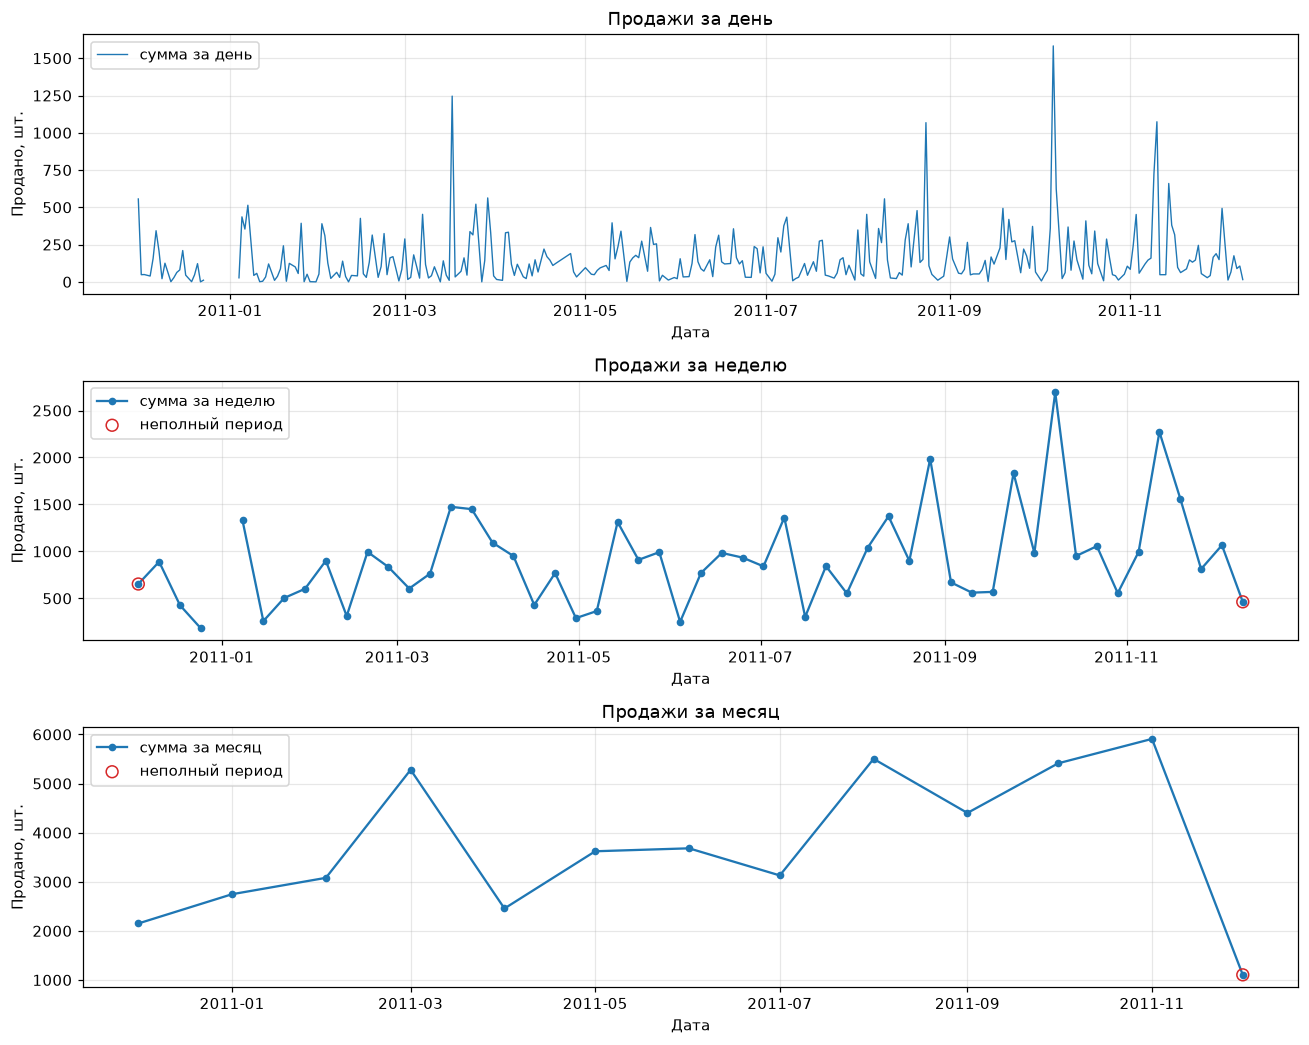

In [8]:
ta.plot_aggregations(aggs, "Продано, шт.");

Три частоты показывают разное:
* **день.** Хорошо видны недельный цикл и отдельные пики до 1 583 шт., но шум очень сильный (коэффициент вариации 1,19);
* **неделя.** День недели усредняется, зато виден рост во второй половине года. Первая неделя неполная, данные начинаются в среду 01.12. Неделя 26.12–01.01 целиком пришлась на каникулы;
* **месяц.** Рост проще всего увидеть здесь: 108 шт. на торговый день в декабре 2010 и 227 в ноябре 2011. Но наблюдений всего 12, а декабрь 2011 обрезан на 9-м числе, поэтому на графике он отмечен как неполный и дальше не используется.

Последний день, 09.12.2011, тоже неполный: данные заканчиваются в 12:50.

## Шаг 2. Качество данных
### Пропуски

In [9]:
pd.DataFrame({
    "день": ta.missing_report(bundle.daily),
    "неделя": ta.missing_report(bundle.weekly["value"]),
    "месяц": ta.missing_report(bundle.monthly["value"]),
})

,день,неделя,месяц
длина ряда,374,54,13
пропусков,69,1,0
доля пропусков,"0,1845","0,01852",0
нулей среди наблюдений,5,0,0
доля нулей,"0,01639",0,0


In [10]:
runs = ta.missing_runs(bundle.daily)
runs["день недели"] = runs["начало"].dt.day_of_week.map(dict(enumerate(ta.WEEKDAYS_RU)))
print("Одиночных пропусков по субботам:", int(((runs["длина"] == 1) & (runs["день недели"] == "Сб")).sum()))
runs[(runs["длина"] > 1) | (runs["день недели"] != "Сб")]

Одиночных пропусков по субботам: 49


,начало,конец,длина,день недели
3,2010-12-24,2011-01-03,11,Пт
19,2011-04-22,2011-04-25,4,Пт
20,2011-04-29,2011-04-30,2,Пт
21,2011-05-02,2011-05-02,1,Пн
26,2011-05-30,2011-05-30,1,Пн
40,2011-08-29,2011-08-29,1,Пн


In [11]:
zeros = bundle.trading[bundle.trading == 0]
print("Торговые дни без продаж товара:", ", ".join(f"{d:%d.%m.%Y} ({ta.WEEKDAYS_RU[d.day_of_week]})" for d in zeros.index))
bundle.weekly[(bundle.weekly["trading_days"] < 6) | ~bundle.weekly["complete"]]

Торговые дни без продаж товара: 22.12.2010 (Ср), 30.01.2011 (Вс), 10.02.2011 (Чт), 13.03.2011 (Вс), 27.03.2011 (Вс)


,value,trading_days,coverage,per_day,complete
Date,,,,,
2010-12-04,653,3,"0,5","217,7",False
2010-12-25,181,5,"0,8333","36,2",True
2011-01-01,NaN,0,0,NaN,False
2011-01-08,1 331,4,"0,6667","332,8",True
2011-04-23,769,5,"0,8333","153,8",True
2011-04-30,290,3,"0,5","96,67",True
2011-05-07,365,5,"0,8333",73,True
2011-06-04,250,5,"0,8333",50,True
2011-09-03,670,5,"0,8333",134,True


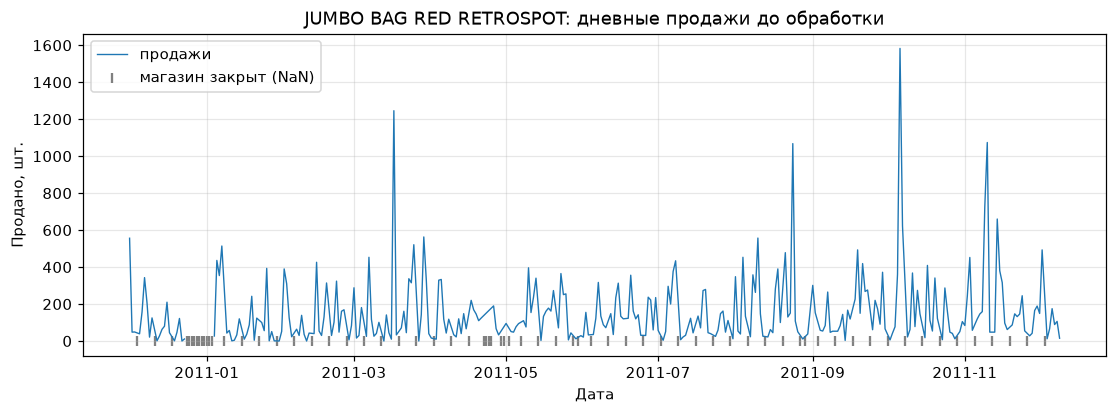

In [12]:
ta.plot_series(bundle.daily, f"{bundle.description}: дневные продажи до обработки", "Продано, шт.",
               closed=bundle.daily.isna());

В дневном ряду 69 пропусков из 374 дней. Все они приходятся на нерабочие дни магазина, ни одного случайного пропуска среди торговых дней нет. Нулей всего 5, из них три в воскресенье. Это реальные дни без спроса, и заменять их нельзя. В недельном ряду пропуск один, это неделя рождественских каникул. В месячном пропусков нет.

Как поступаем с пропусками:
* для описательных статистик и тестов, которые не требуют регулярной сетки, берём только фактические наблюдения (`bundle.trading`) и ничего не заполняем;
* STL, ACF и разности требуют ряд без пропусков с постоянным шагом. Если просто выкинуть нерабочие дни, после каждого праздника недельный цикл сдвинется по фазе, и сезонная разность начнёт сравнивать, например, пятницу со вторником. Поэтому строим сетку «все дни, кроме субботы». Тогда на ней остаются только праздники;
* 11 дней рождественских каникул подряд разумно не заполнить. Для этих методов ряд начинается с 04.01.2011, а заканчивается 08.12.2011, чтобы не брать неполный последний день. На оставшейся сетке пропущено 7 праздничных дней (2,4 %). Их заполняем средним того же дня недели соседних недель и помечаем. Для статистик эти точки не используются.

In [13]:
grid = ta.weekly_grid(bundle.daily, start="2011-01-04", end="2011-12-08")
grid_filled, grid_mask = ta.fill_for_decomposition(grid, PERIOD)
print(f"Сетка Вс–Пт: {len(grid)} дней, заполнено праздников: {int(grid_mask.sum())}")
pd.DataFrame({"заполнено": grid_filled[grid_mask],
              "день недели": [ta.WEEKDAYS_RU[d.day_of_week] for d in grid_filled[grid_mask].index]})

Сетка Вс–Пт: 291 дней, заполнено праздников: 7


,заполнено,день недели
Date,,
2011-04-22,66,Пт
2011-04-24,"157,5",Вс
2011-04-25,169,Пн
2011-04-29,94,Пт
2011-05-02,76,Пн
2011-05-30,244,Пн
2011-08-29,92,Пн


### Выбросы

Сравним три метода:
* **IQR по всему ряду** — правило Тьюки. Оно грубое: не учитывает ни тренд, ни день недели;
* **фильтр Хампеля** — отклонение от скользящей медианы окна ±7 торговых дней больше 3·1,4826·MAD. Метод локальный, а медиана и MAD сами устойчивы к выбросам;
* **фильтр Хампеля на шкале log(1 + x)** — тот же метод, но отклонения считаются в относительных величинах. При мультипликативном шуме это честнее, потому что пик в 3 раза выше обычного уровня в январе и в ноябре весит одинаково.

In [14]:
daily_obs = bundle.trading
outlier_masks = {
    "IQR (весь ряд)": ta.iqr_outliers(daily_obs, k=1.5),
    "Хампель": ta.hampel_outliers(daily_obs, window=7, n_sigmas=3),
    "Хампель, log": ta.hampel_outliers(np.log1p(daily_obs), window=7, n_sigmas=3),
}
print({k: int(v.sum()) for k, v in outlier_masks.items()})
outliers = ta.outlier_table(daily_obs, outlier_masks)
outliers.head(10)

{'IQR (весь ряд)': 14, 'Хампель': 29, 'Хампель, log': 8}


,значение,IQR (весь ряд),Хампель,"Хампель, log",методов
Date,,,,,
2011-10-06,1 583,True,True,False,2
2011-03-17,1 246,True,True,False,2
2011-11-10,1 074,True,True,False,2
2011-08-24,1 068,True,True,False,2
2011-11-09,725,True,True,False,2
2011-11-14,660,True,True,False,2
2011-10-07,623,True,True,False,2
2011-03-29,563,True,False,False,1
2011-08-10,557,True,False,False,1


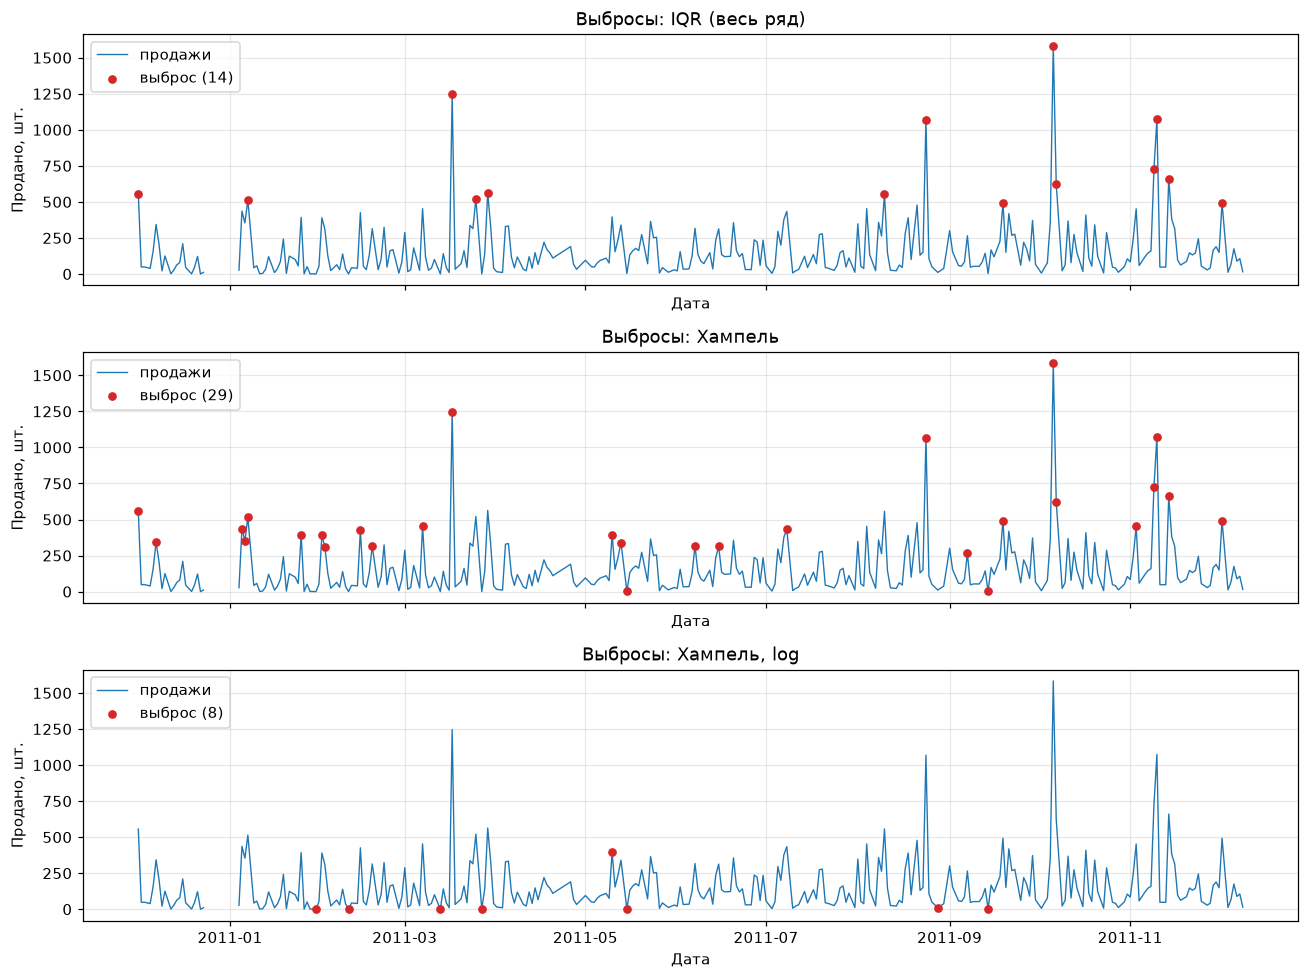

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (name, mask) in zip(axes, outlier_masks.items()):
    ta.plot_series(daily_obs, f"Выбросы: {name}", "Продано, шт.", ax=ax, mark=mask,
                   mark_label=f"выброс ({int(mask.sum())})")
fig.tight_layout()

In [16]:
outliers[outliers["Хампель, log"]]

,значение,IQR (весь ряд),Хампель,"Хампель, log",методов
Date,,,,,
2011-05-10,396,False,True,True,2
2011-08-28,11,False,False,True,1
2011-05-15,3,False,True,True,2
2011-09-14,3,False,True,True,2
2011-03-13,0,False,False,True,1
2011-01-30,0,False,False,True,1
2011-03-27,0,False,False,True,1
2011-02-10,0,False,False,True,1


На исходной шкале методы находят от 14 до 29 точек, почти все сверху, то есть они размечают правый хвост распределения. На лог-шкале крупные пики выбросами уже не считаются. Например, 1 583 шт. 06.10 — это в 17 раз больше локальной медианы (91 шт.), но при обычном для этого ряда разбросе порог фильтра на лог-шкале соответствует отклонению примерно в 27–30 раз. Вместо пиков выделяются дни почти без продаж (0–11 шт., пять из семи — воскресенья) и один день 10.05, когда на фоне спокойного мая продали 396 шт.

Чтобы понять природу пиков, посмотрим на строки заказов в эти дни.

In [17]:
peak_days = daily_obs.nlargest(4).index
ta.transactions_on(clean, STOCK_CODE, peak_days).groupby("Date").head(3)

,Date,InvoiceNo,CustomerID,Country,Quantity,UnitPrice
121857,2011-03-17,546789,15 769,United Kingdom,1200,"1,65"
123569,2011-03-17,546899,14 298,United Kingdom,30,"1,65"
121824,2011-03-17,546786,16 523,United Kingdom,10,"1,95"
311678,2011-08-24,564312,15 769,United Kingdom,300,"1,79"
311668,2011-08-24,564310,15 769,United Kingdom,200,"1,79"
311672,2011-08-24,564311,15 769,United Kingdom,200,"1,79"
380505,2011-10-06,569815,15 838,United Kingdom,1000,"1,79"
381313,2011-10-06,569857,12 939,United Kingdom,200,"1,95"
380254,2011-10-06,569740,15 769,United Kingdom,140,"1,79"
454472,2011-11-10,575582,16 986,United Kingdom,1000,"1,79"


In [18]:
profile = ta.order_profile(clean, STOCK_CODE, big=BIG_LINE)
tx = clean[clean["StockCode"] == STOCK_CODE]
big = tx[tx["Quantity"] >= BIG_LINE]
print(f"Строк ≥ {BIG_LINE} шт.: {len(big)} из {len(tx)} ({len(big) / len(tx):.1%}), "
      f"это {big['Quantity'].sum() / tx['Quantity'].sum():.1%} всех штук; клиентов: {big['CustomerID'].nunique()}")
profile

Строк ≥ 200 шт.: 56 из 2112 (2.7%), это 33.0% всех штук; клиентов: 20


,строк,клиентов,штук,доля штук в строках ≥ 200,доля топ-3 клиентов,медианная цена
Date,,,,,,
2010-12-01,120,77,2151,"0,2325","0,3719","1,95"
2011-01-01,119,73,2747,"0,2912","0,3276","1,95"
2011-02-01,123,78,3080,"0,1948","0,2597","1,95"
2011-03-01,172,106,5280,"0,5134","0,3977","1,95"
2011-04-01,123,83,2456,"0,1629","0,2443","2,08"
2011-05-01,189,122,3621,"0,2762","0,1657","2,08"
2011-06-01,183,115,3681,"0,2445","0,1902","2,08"
2011-07-01,184,119,3129,"0,2237","0,2237","2,08"
2011-08-01,180,134,5502,"0,418","0,2545","2,08"


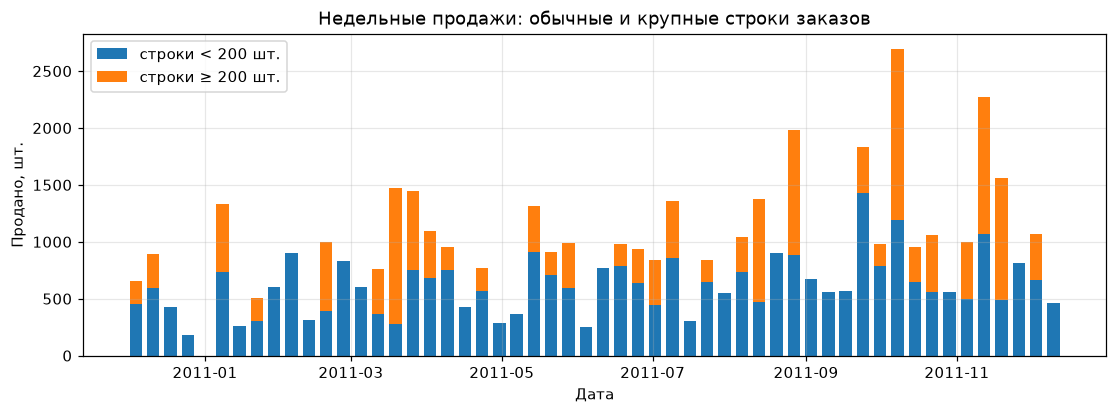

In [19]:
bulk = ta.split_bulk(clean, STOCK_CODE, calendar, big=BIG_LINE)
bulk.columns = [f"строки < {BIG_LINE} шт.", f"строки ≥ {BIG_LINE} шт."]
ta.plot_bulk(bulk, "W-SAT", "Недельные продажи: обычные и крупные строки заказов", "Продано, шт.");

Каждый из четырёх крупнейших пиков дают одна-три строки по 200–1 200 шт. от одного оптового клиента: 15769 (17.03, 24.08), 15838 (06.10), 16986 (10.11). Цена в этих строках оптовая, £1,65–1,79 против £1,95–2,08. Это настоящие заказы, ошибок ввода здесь нет. Всего за год было 56 крупных строк (2,7 % строк) от 20 клиентов, и на них пришлась треть всех проданных штук. В отдельные месяцы, например в марте, — до половины объёма.

**Решение: выбросы не удаляем и не корректируем.**
* Это реальный спрос. Если заменить его медианой, уровень продаж окажется заниженным, а прогноз по такому ряду не покроет оптовые заказы, которые повторяются: клиент 15769 делал крупные заказы почти каждый месяц.
* Влияние пиков на анализ снижаем по-другому: дальше работаем на шкале log(1 + x), а в шаге 5 проверяем, меняются ли выводы, если пики заменить скользящей медианой или вообще убрать крупные строки.
* Для моделирования естественно разделить ряд на розничную часть (строки < 200 шт.) и оптовую, которая прерывиста и зависит от нескольких клиентов. Но это уже вопрос постановки задачи прогноза, а не очистки данных.

Дни почти без продаж, найденные на лог-шкале, тоже реальны (в основном это воскресенья, когда спрос и так минимален) и остаются как есть.

## Шаг 3. Визуальный и описательный анализ

In [20]:
weekly_ok = bundle.weekly[bundle.weekly["complete"]]
monthly_ok = bundle.monthly[bundle.monthly["complete"]]
ta.describe_many({
    "день": daily_obs,
    "неделя (сумма)": weekly_ok["value"],
    "неделя (на торг. день)": weekly_ok["per_day"],
    "месяц (сумма)": monthly_ok["value"],
})

,день,неделя (сумма),неделя (на торг. день),месяц (сумма)
наблюдений,305,51,51,12
среднее,"158,9","928,6","159,3",3 947
медиана,105,900,"150,2",3 651
ст. откл.,"189,1","513,9","86,87",1 310
минимум,0,181,"36,2",2 151
Q1,43,565,"95,75",2 997
Q3,220,1 061,"176,8",5 313
максимум,1 583,2 693,"448,8",5 909
коэф. вариации,"1,19","0,5534","0,5452","0,3319"
асимметрия,"3,223","1,209","1,222","0,2029"


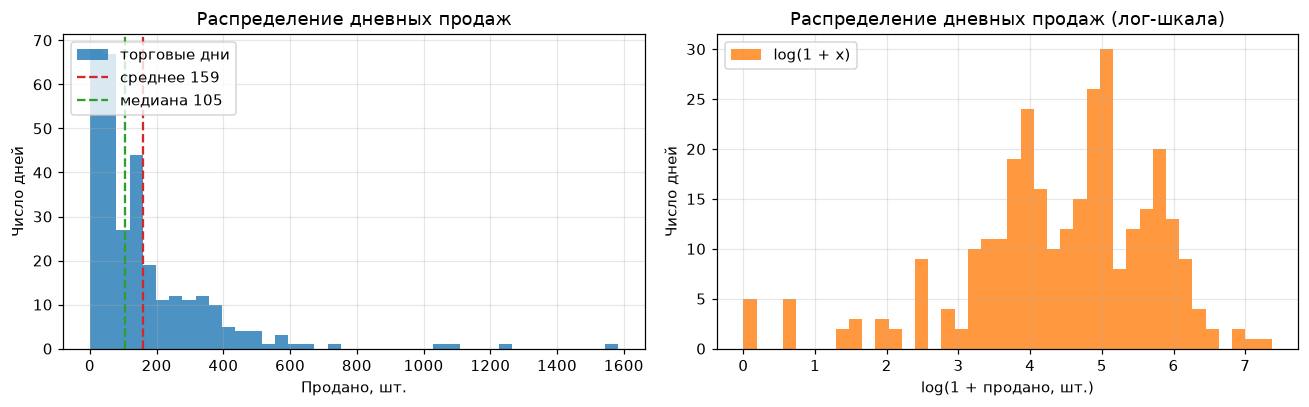

In [21]:
ta.plot_distribution(daily_obs, "Распределение дневных продаж", "Продано, шт.");

Дневные продажи сильно скошены вправо: среднее 159 шт., медиана 105, асимметрия 3,2, эксцесс 16. Среднее тянут вверх оптовые дни, поэтому типичный день лучше описывает медиана. После log(1 + x) распределение становится почти симметричным, если не считать нескольких дней с 0–3 шт.

Дополнительные характеристики для спроса — классификация Syntetos–Boylan:
* **ADI** — средний интервал между ненулевыми продажами. На дневном ряду он 1,02, то есть товар продаётся почти каждый день;
* **CV²** — квадрат коэффициента вариации ненулевых продаж. Он равен 1,38 при пороге 0,49, то есть объём от дня к дню сильно скачет.

Вместе это даёт тип «неустойчивый» (erratic): спрос регулярный по факту, но непредсказуемый по объёму. При агрегации по неделям CV² падает до 0,31, а по месяцам до 0,11, и спрос становится «ровным». Так что прогнозировать недели заметно проще, чем дни.

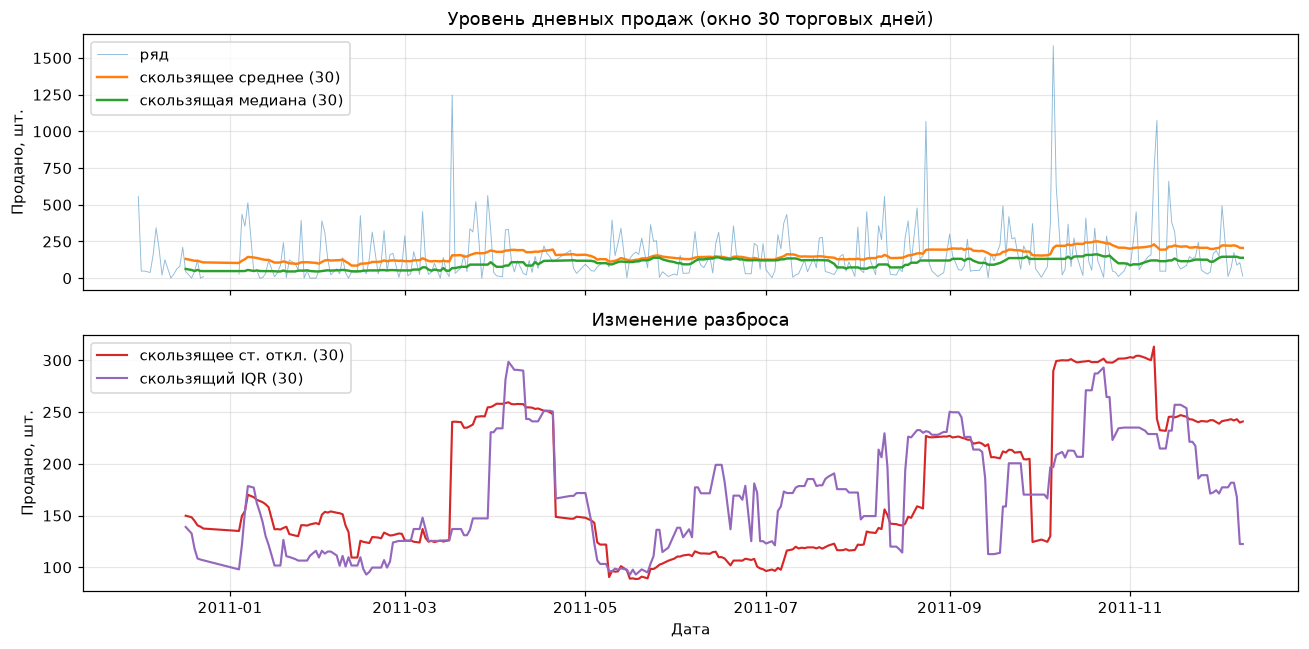

In [22]:
rs = ta.rolling_stats(daily_obs, 30)
ta.plot_rolling(rs, 30, "Уровень дневных продаж (окно 30 торговых дней)", "Продано, шт.");

In [23]:
print("Исходная шкала"); display(ta.compare_halves(daily_obs))
print("Шкала log(1 + x)"); display(ta.compare_halves(np.log1p(daily_obs)))
print(f"λ Бокса–Кокса для (x + 1): {ta.boxcox_lambda(daily_obs):.2f}".replace(".", ","))

Исходная шкала


,1-я половина,2-я половина,p-value
начало,2010-12-01,2011-06-14,NaN
медиана,"78,5",122,"0,004679"
ст. откл.,"159,7","212,2","0,1686"


Шкала log(1 + x)


,1-я половина,2-я половина,p-value
начало,2010-12-01,2011-06-14,NaN
медиана,"4,376","4,812","0,004679"
ст. откл.,"1,486","1,113","0,01345"


λ Бокса–Кокса для (x + 1): 0,22


**Уровень.** Скользящая медиана растёт примерно с 50 шт. в январе до 120–140 к осени. Медиана второй половины ряда (122) выше, чем первой (78,5). Тест Манна–Уитни даёт p = 0,005, так что уровень не постоянен.

**Разброс.** Скользящее стандартное отклонение ведёт себя ступеньками: оно прыгает, когда в окно попадает оптовый пик, и падает через 30 дней, когда пик из окна выходит. IQR к отдельным пикам нечувствителен. Он тоже колеблется, но в целом растёт вместе с уровнем: около 100–130 шт. в январе–феврале и 170–250 осенью. Тест Брауна–Форсайта (он сравнивает абсолютные отклонения от медианы) на исходной шкале разницы в разбросе половин не находит (p = 0,17): основную часть отклонений в обеих половинах дают оптовые пики. Но по IQR видно, что разброс растёт пропорционально уровню, значит, шум мультипликативный. Оценка λ Бокса–Кокса около 0,2, это ближе к логарифму, чем к корню. Поэтому дальше работаем с log(1 + x). На лог-шкале разброс второй половины даже немного меньше первой: в январе–марте было несколько дней с 0–3 шт., а на лог-шкале такие значения сильно растягиваются.

,дней,среднее,медиана,доля нулей
Пн,47,"164,6",105,0
Вт,52,"178,4","150,5",0
Ср,53,"191,4",135,"0,01887"
Чт,53,"219,1",134,"0,01887"
Пт,50,"137,4",83,0
Вс,50,"56,72",30,"0,06"


Краскел–Уоллис: {'H': '47,07', 'p-value': '5,492e-09', 'групп': '6'}


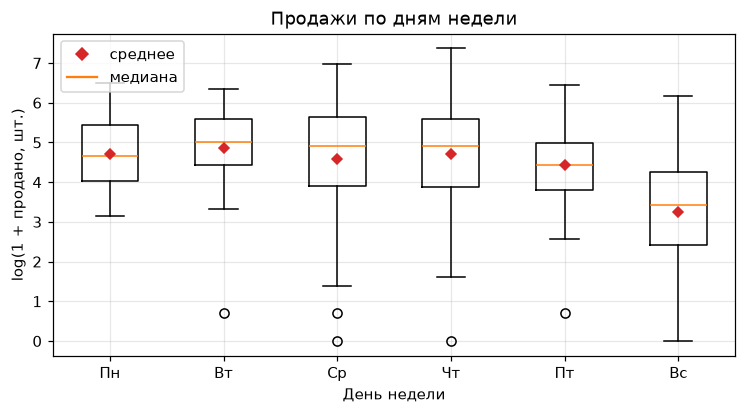

In [24]:
display(ta.weekday_profile(bundle.daily))
print("Краскел–Уоллис:", {k: _fmt(v) for k, v in ta.weekday_test(bundle.daily).items()})
ta.plot_weekday(bundle.daily, "Продажи по дням недели", "log(1 + продано, шт.)");

,ACF
lag 1,"0,1208"
lag 6,"0,1596"
lag 12,"0,1885"
lag 18,"0,08265"
lag 24,"0,2131"
граница 95%,"0,1149"


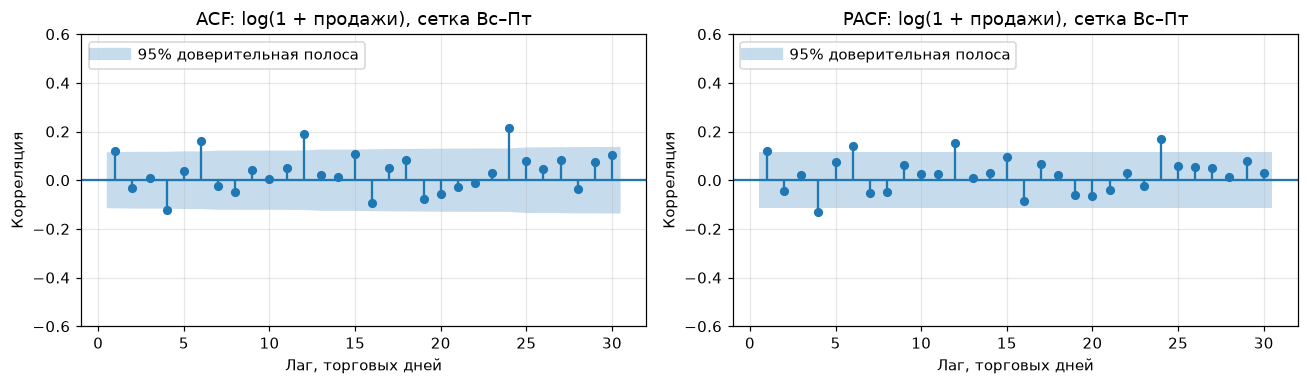

In [25]:
log_grid = np.log1p(grid_filled)
ta.plot_acf_pacf(log_grid, 30, "log(1 + продажи), сетка Вс–Пт");
ta.acf_at(log_grid, [1, 6, 12, 18, 24]).to_frame("ACF")

**День недели.** Воскресенье резко отличается от остальных дней: медиана 30 шт. против 83–150 в будни, а нули случаются в основном по воскресеньям. Пятница тоже ниже среды и четверга. Критерий Краскела–Уоллиса отвергает равенство распределений по дням недели (p ≈ 5·10⁻⁹).

**Автокорреляция.** На сетке «Вс–Пт» значимые пики ACF стоят на лагах 6, 12 и 24, то есть кратных неделе. Остальные лаги, кроме 1 и 4, лежат внутри полосы. Это повторяющаяся недельная структура. Короткая память при этом слабая: ACF на лаге 1 равна всего 0,12.

## Шаг 4. Декомпозиция

**Метод:** STL (Seasonal-Trend decomposition using LOESS) в робастном варианте. Классическая аддитивная декомпозиция через скользящие средние здесь хуже по трём причинам: она чувствительна к оптовым пикам, теряет точки на краях и считает сезонный профиль одинаковым на всём ряду. STL с `robust=True` уменьшает вес пиков при оценке компонент и позволяет профилю меняться.

**Ряд и параметры:** log(1 + дневные продажи) на сетке «Вс–Пт». Логарифм делает шум и сезонность аддитивными. Параметры:
* период 6, это торговая неделя;
* окно сезонного сглаживания 13, около трёх месяцев, чтобы профиль менялся медленно;
* окно тренда 31 торговый день, около пяти недель.

Годовую сезонность так выделить нельзя: для неё нужно хотя бы два полных года, а данных чуть больше одного. Поэтому для недельного ряда выделяем только тренд.

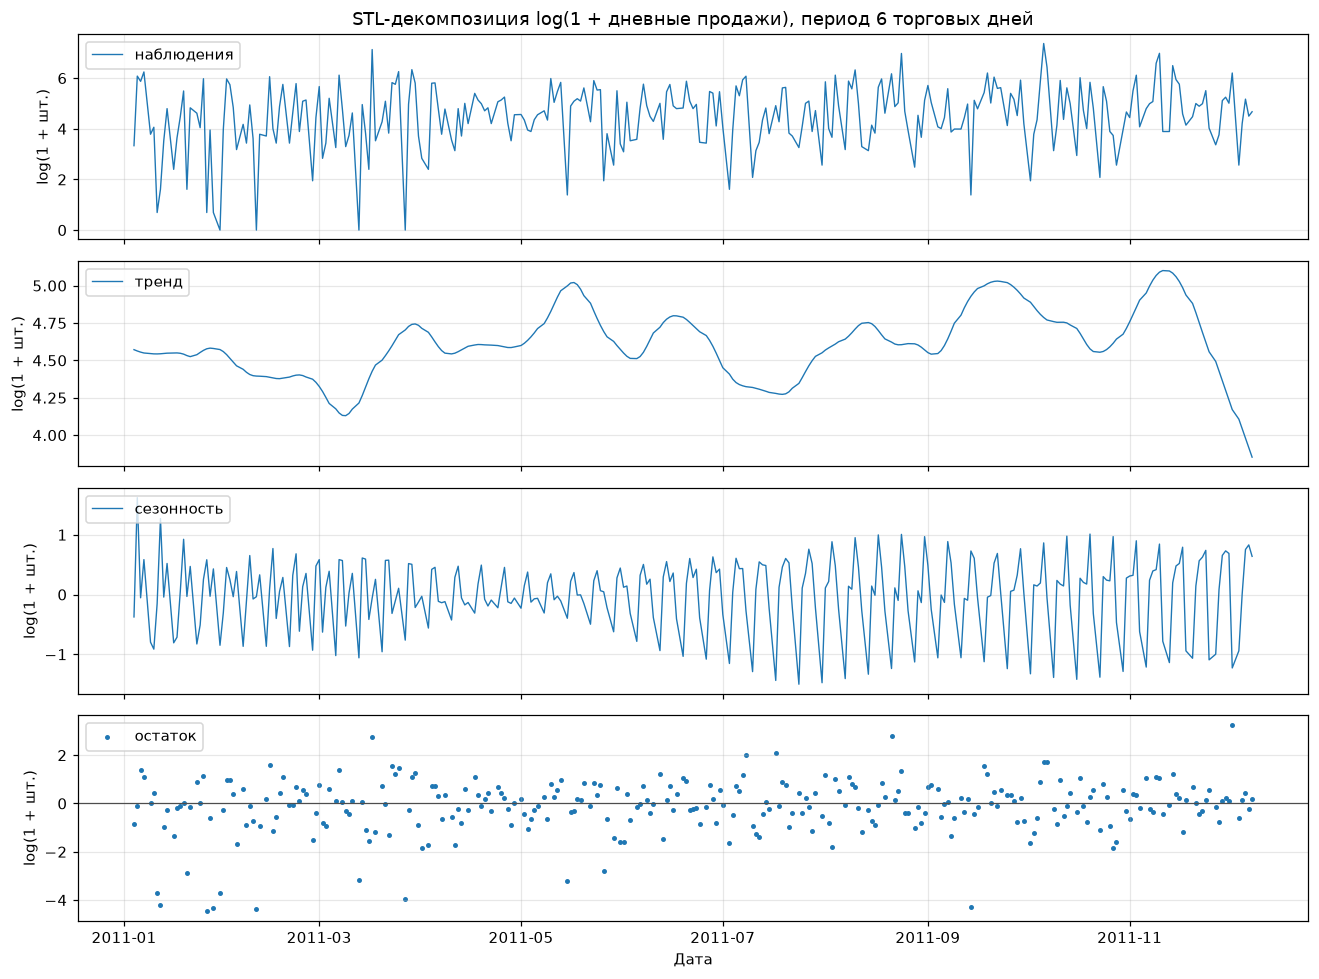

In [26]:
stl_res = ta.stl_decompose(log_grid, PERIOD, **STL_KW)
ta.plot_stl(stl_res, log_grid.index, "STL-декомпозиция log(1 + дневные продажи), период 6 торговых дней",
            "log(1 + шт.)");

In [27]:
strength = ta.component_strength(stl_res)
perm = ta.seasonal_strength_null(log_grid, PERIOD, n_perm=300, seed=42, **STL_KW)
pd.Series({**strength, **{f"перестановки: {k}": v for k, v in perm.items()}}).to_frame("значение")

,значение
сила тренда,"0,05062"
сила сезонности,"0,1996"
перестановки: F_s,"0,1963"
перестановки: F_s при H0 (95%),"0,151"
перестановки: p-value,"0,003322"


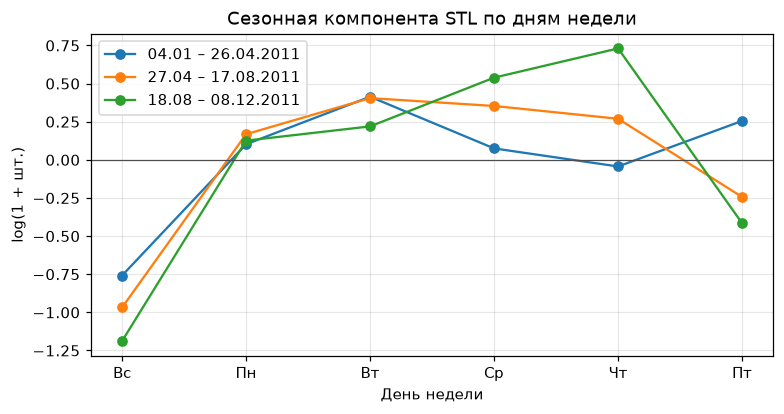

In [28]:
ta.plot_seasonal_profile(stl_res, log_grid.index, "Сезонная компонента STL по дням недели", "log(1 + шт.)");

Чтобы понять, насколько выражена каждая компонента, считаем силу по Ван–Смиту–Хайндману (Wang, Smith & Hyndman): $F = \max(0,\ 1 - \operatorname{Var}(R) / \operatorname{Var}(X + R))$. Сильные компоненты дают значения ближе к 1.

Даже у ряда без всякой сезонности STL выделит какую-то «сезонную» компоненту из шума, поэтому одного значения F мало. Проверяем значимость перестановками: внутри каждой недели значения перемешиваются случайно. Уровень недели при этом сохраняется, а привязка к дню недели разрушается.

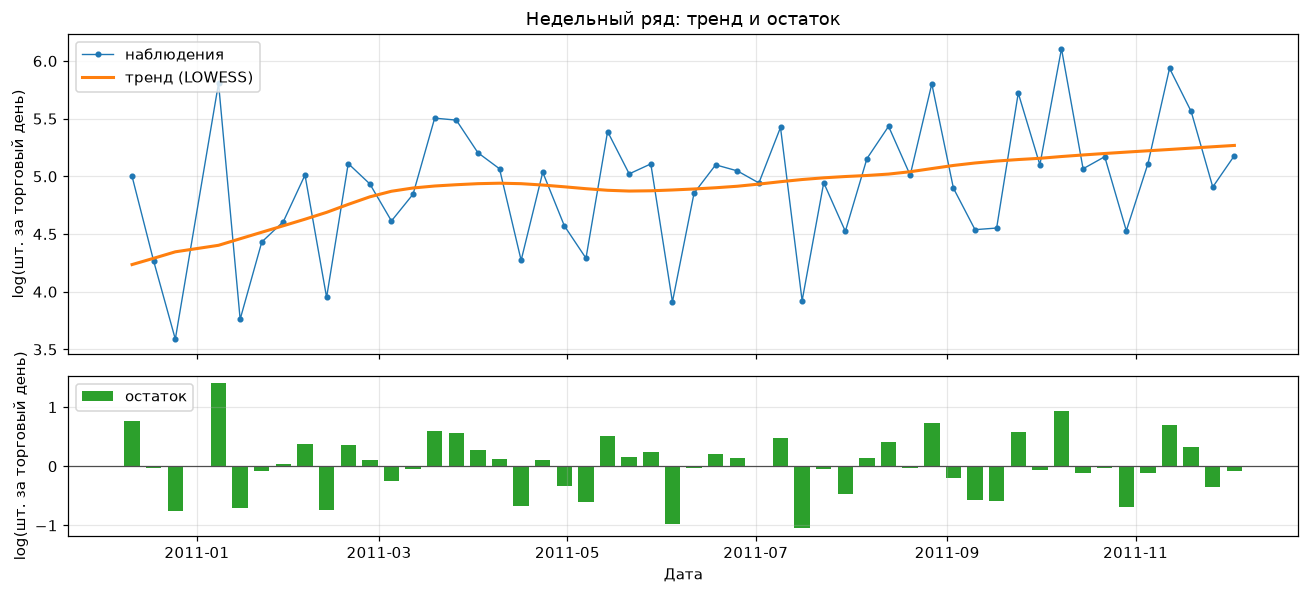

In [29]:
weekly_trend = ta.trend_lowess(np.log(weekly_ok["per_day"]), frac=0.4)
ta.plot_trend_lowess(weekly_trend, "Недельный ряд: тренд и остаток", "log(шт. за торговый день)");

**Тренд.** На дневном ряду тренд STL колеблется в диапазоне 4,1–5,1, то есть примерно 60–165 шт. в день. Подъёмы приходятся на март, май, август и октябрь–ноябрь, и почти все они связаны с периодами оптовых заказов. Сила тренда на дневном ряду мала, 0,05: день ото дня шум гораздо сильнее медленных изменений уровня. На недельном ряду тренд LOWESS виден лучше. Уровень растёт с января до апреля, летом стоит на месте, а с августа снова растёт. По тренду LOWESS он поднялся примерно с 70 до 195 шт. на торговый день. Начало тренда занижено тихими предрождественскими неделями. По месячным данным рост примерно двукратный: 108 → 227. Падение тренда STL в последние дни — краевой эффект окна, а не реальное снижение.

**Недельная сезонность есть.** Сила сезонности 0,20 невелика, но в перестановках такое значение получается редко: 95-й перцентиль 0,15, p ≈ 0,003. Это согласуется с критерием Краскела–Уоллиса и с пиками ACF на лагах 6, 12 и 24. **Период — одна торговая неделя, 6 рабочих дней.** Профиль меняется во времени, это видно и по растущей амплитуде сезонной компоненты, и по графику профиля. Воскресный провал углубляется (с −0,8 до −1,2 в лог-единицах, то есть в 2,1 раза ниже среднего против 3,3 раза). Пятница сначала была выше среднего, а к осени стала ниже, и пик недели сместился на четверг.

**Годовая сезонность не установлена.** Рост к концу 2011 года похож на предрождественский сезон. Но в декабре 2010 продажи на торговый день (108) почти не отличались от января–февраля (114–128). Значит, по одному году нельзя отличить сезон от общего роста спроса на товар.

**Остаток** в основном симметричен. Крупные отрицательные значения — те же дни с 0–3 шт., которые нашёл фильтр Хампеля на лог-шкале.

## Шаг 5. Стационарность

Используем два теста с противоположными нулевыми гипотезами:
* **ADF** (расширенный тест Дики–Фуллера), H0: есть единичный корень. Если p < 0,05, единичного корня нет;
* **KPSS** (Квятковского–Филлипса–Шмидта–Шина), H0: ряд стационарен. Если p < 0,05, стационарность отвергается. В statsmodels p-value KPSS обрезается до диапазона [0,01; 0,1].

Каждый тест проводим в двух вариантах: со средним (`c`, стационарность вокруг константы) и с линейным трендом (`ct`, стационарность вокруг тренда). Комбинация «ADF отвергает H0, KPSS (c) отвергает H0, KPSS (ct) не отвергает» означает **тренд-стационарный** ряд. Единичного корня у такого ряда нет, а среднее меняется детерминированно.

Ряды берём на сетке «Вс–Пт» без пропусков (291 день): исходную шкалу и log(1 + x).

In [30]:
pd.concat({
    "c": ta.stationarity_report({"день, шт.": grid_filled, "день, log": log_grid}, regression="c"),
    "ct": ta.stationarity_report({"день, шт.": grid_filled, "день, log": log_grid}, regression="ct"),
}, names=["детерминированная часть"])

n  ADF стат.     ADF p  ADF лагов  KPSS стат.  KPSS p                                                                                      вывод
детерминированная часть ряд                                                                                                                                                          
c                       день, шт.  291     -12,23 1,062e-22          1      0,4776 0,04672  противоречие: нет единичного корня, но есть сдвиг уровня/тренд или неоднородная дисперсия
                        день, log  291      -3,88  0,002185         11       1,102    0,01  противоречие: нет единичного корня, но есть сдвиг уровня/тренд или неоднородная дисперсия
ct                      день, шт.  291     -12,52  6,23e-20          1     0,03762     0,1                                                                                стационарен
                        день, log  291     -7,098 8,492e-09          7     0,07391     0,1                                                                                стационарен

In [31]:
weekly_log = np.log(weekly_ok["per_day"])
pd.concat({
    "c": ta.stationarity_report({"неделя, log шт./день": weekly_log, "месяц, шт./день": monthly_ok["per_day"]},
                                regression="c", maxlag=2),
    "ct": ta.stationarity_report({"неделя, log шт./день": weekly_log}, regression="ct", maxlag=2),
}, names=["детерминированная часть"])

n  ADF стат.     ADF p  ADF лагов  KPSS стат.  KPSS p                                                                                      вывод
детерминированная часть ряд                                                                                                                                                                    
c                       неделя, log шт./день  51     -6,959 9,291e-10          0      0,6757 0,01575  противоречие: нет единичного корня, но есть сдвиг уровня/тренд или неоднородная дисперсия
                        месяц, шт./день       12     -1,931    0,3177          0      0,5291 0,03511                                                           нестационарен (единичный корень)
ct                      неделя, log шт./день  51     -8,268 1,722e-11          0     0,05421     0,1                                                                                стационарен

**Исходный ряд нестационарен по среднему, но единичного корня у него нет.**
* ADF отвергает единичный корень на всех вариантах дневного ряда, на исходной шкале с запасом (статистика −12).
* KPSS со средним отвергает стационарность для лог-ряда (p ≤ 0,01), а на исходной шкале — на границе (p ≈ 0,05). На исходной шкале оптовые пики маскируют сдвиг уровня, после логарифма он виден лучше.
* Если добавить линейный тренд, оба теста согласны: ряд стационарен вокруг тренда.

Итог для дневного ряда: он **тренд-стационарен**. Это согласуется с ростом медианы в шаге 3.

Недельный ряд ведёт себя так же. ADF отвергает единичный корень, KPSS (c) отвергает стационарность (p ≈ 0,016), а с трендом ряд стационарен.

У месячного ряда всего 12 точек, и тесты там почти бесполезны: ADF не отвергает единичный корень, KPSS отвергает стационарность. Формально ряд нестационарен, но при такой длине у ADF очень низкая мощность, поэтому как самостоятельное доказательство это не годится. Вывод делаем по дневному и недельному рядам.

Ряд нестационарен, поэтому нужно его преобразовать. Сравним три варианта:
1. первую разность log-ряда;
2. сезонную разность с лагом 6;
3. удаление линейного тренда.

Для третьего варианта отдельный тест на остатках не нужен. Тест `ct` выше — это как раз тест остатков после вычитания тренда, причём с правильными критическими значениями. Если тестировать остатки с `c`, критические значения окажутся слишком мягкими.

In [32]:
transformed = {
    "log, разность 1": ta.difference(log_grid, 1),
    "log, сезонная разность 6": ta.difference(log_grid, PERIOD),
}
ta.stationarity_report(transformed, regression="c")

,n,ADF стат.,ADF p,ADF лагов,KPSS стат.,KPSS p,вывод
ряд,,,,,,,
"log, разность 1",290,"-8,796","2,174e-14",13,"0,03636","0,1",стационарен
"log, сезонная разность 6",285,"-7,993","2,452e-12",11,"0,01563","0,1",стационарен


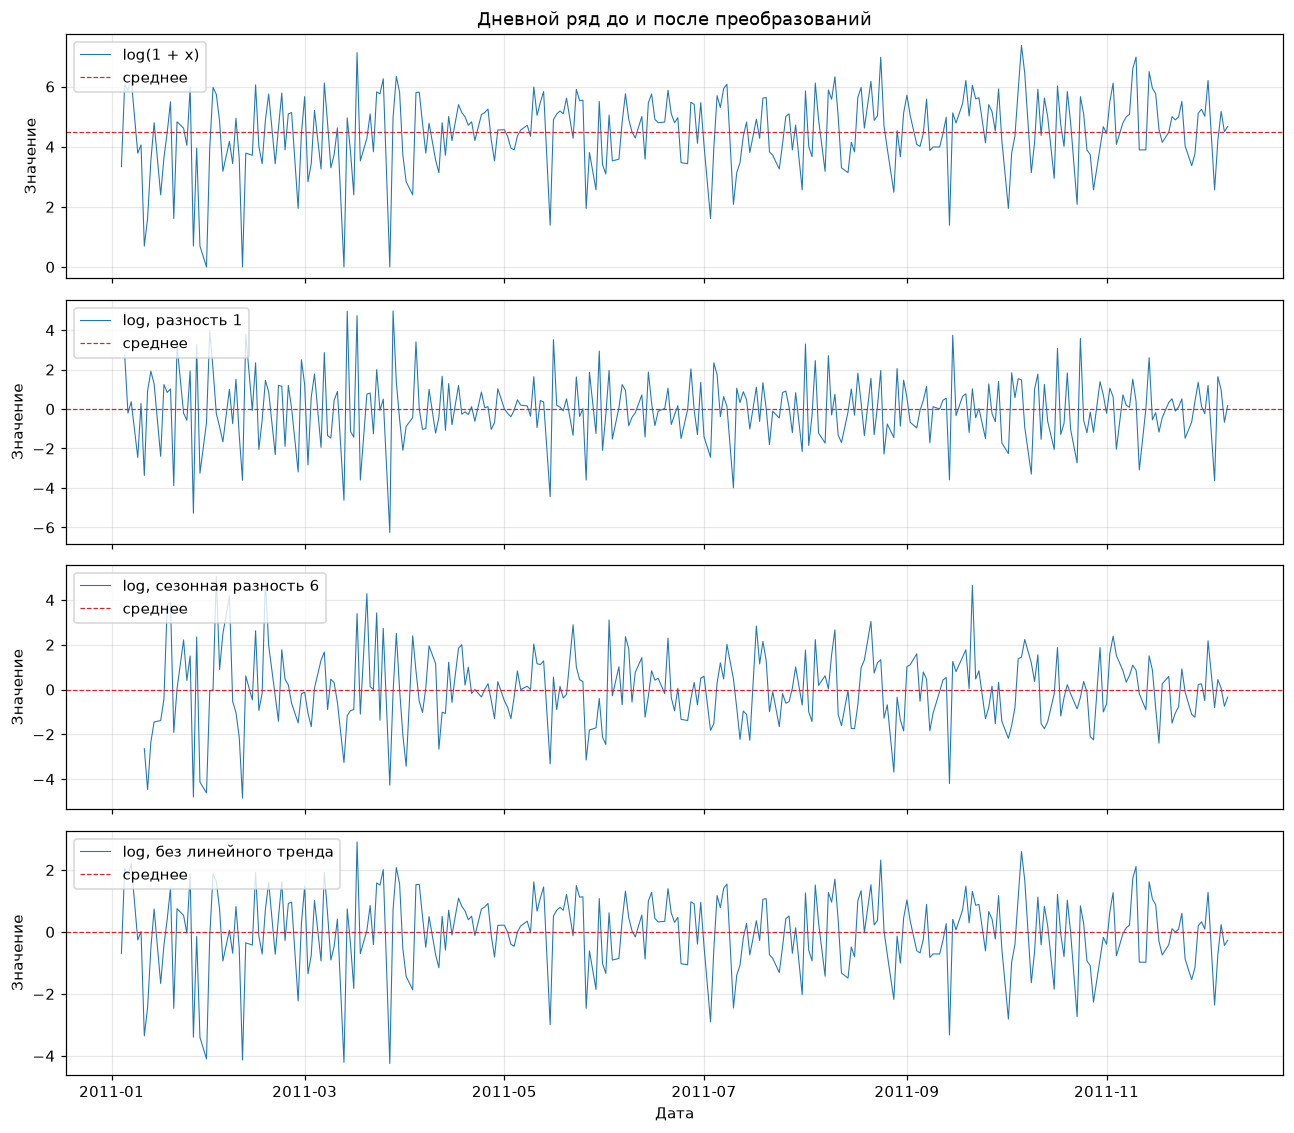

In [33]:
detrended = ta.linear_detrend(log_grid)
ta.plot_transform_comparison({"log(1 + x)": log_grid, **transformed, "log, без линейного тренда": detrended},
                             "Дневной ряд до и после преобразований");

In [34]:
pd.DataFrame({name: ta.acf_at(s, [1, 2, 6, 12])
              for name, s in {**transformed, "log, без линейного тренда": detrended}.items()})

,"log, разность 1","log, сезонная разность 6","log, без линейного тренда"
lag 1,"-0,4106","0,1357","0,08269"
lag 2,"-0,11","0,06422","-0,07768"
lag 6,"0,1678","-0,5105","0,1175"
lag 12,"0,1751","0,08803","0,155"
граница 95%,"0,1151","0,1161","0,1149"


In [35]:
ta.stationarity_report({"неделя, log, разность 1": ta.difference(weekly_log),
                        "месяц, разность 1": ta.difference(monthly_ok["per_day"])}, maxlag=2)

,n,ADF стат.,ADF p,ADF лагов,KPSS стат.,KPSS p,вывод
ряд,,,,,,,
"неделя, log, разность 1",50,"-6,772","2,628e-09",2,"0,1484","0,1",стационарен
"месяц, разность 1",11,"-3,361","0,01235",1,"0,3686","0,09067",стационарен


После любой разности оба теста говорят «стационарен». Но для тренд-стационарного ряда разность — лишнее преобразование, и это видно по автокорреляции:
* после первой разности ACF на лаге 1 равна −0,41. У белого шума после разности она была бы −0,5, и это классический признак **передифференцирования**: в ряд добавлена необратимая MA-компонента;
* после сезонной разности ACF на лаге 6 равна −0,51, то есть та же картина для сезонности. Недельный профиль меняется медленно, и сезонного единичного корня у ряда нет.

Ряд без линейного тренда стационарен по тесту `ct` (выше). Значимой автокорреляции на лаге 1 у него нет, остаётся только недельная структура на лагах 6 и 12.

**Выбранное преобразование: log(1 + x) и удаление тренда.** Логарифм стабилизирует мультипликативный разброс. Тренд лучше задать в модели явно (как регрессор или сглаженный уровень), а недельную сезонность — фиктивными переменными дня недели или сезонной компонентой STL. Если нужна модель класса ARIMA с разностью, подойдёт d = 1, но тогда обязательно нужен MA-член, который поглотит наведённую автокорреляцию. Недельный ряд после первой разности тоже стационарен. Месячный ряд после разности формально проходит тесты, но 11 точек для выводов мало.

### Чувствительность к выбросам

Проверим, держатся ли выводы шагов 4–5, если ослабить влияние оптовых заказов. Сравниваем три варианта ряда:
1. исходный;
2. пики, найденные фильтром Хампеля, заменены скользящей медианой;
3. только строки заказов меньше 200 шт., то есть розничная часть спроса.

In [36]:
retail_grid, _ = ta.fill_for_decomposition(ta.weekly_grid(bulk.iloc[:, 0], "2011-01-04", "2011-12-08"), PERIOD)
variants = {
    "исходный": grid_filled,
    "пики заменены медианой": ta.cap_outliers(grid_filled, ta.hampel_outliers(grid_filled, 7, 3)),
    f"только строки < {BIG_LINE} шт.": retail_grid,
}
ta.robustness_table(variants, PERIOD, **STL_KW)

,ADF p (c),KPSS p (c),ADF p (ct),KPSS p (ct),"KPSS p, разность",ACF(1) разности,сила сезонности
исходный,"0,002185","0,01","8,492e-09","0,1","0,1","-0,4106","0,1996"
пики заменены медианой,"0,006296","0,01","1,257e-05","0,01","0,1","-0,4037","0,2268"
только строки < 200 шт.,"0,002271","0,01","0,0004225","0,1","0,1","-0,4032","0,2064"


Устойчивые выводы:
* единичного корня нет (ADF p < 0,01 во всех вариантах);
* среднее не постоянно (KPSS (c) p = 0,01);
* после первой разности ряд стационарен, но ACF(1) около −0,4, то есть ряд передифференцирован;
* недельная сезонность сохраняется, сила 0,20–0,23.

Чувствительный вывод — форма тренда. Если пики заменить медианой, KPSS (ct) отвергает стационарность вокруг линейного тренда (p = 0,01). Значит, линейный тренд — лишь приближение, а рост идёт рывками (весна, август, октябрь–ноябрь). Для прогноза лучше гибкий тренд, например кусочно-линейный или сглаженный, чем одна прямая.

## Шаг 6. Функции и классы

Все операции анализа лежат в модуле `ts_analysis.py`, ноутбук только вызывает их. Модуль разбит на блоки по шагам анализа. Класс `SeriesBundle` собирает ряды товара сразу на всех частотах: `SeriesBundle.build(clean, "85099B")`. Ниже список функций и классов модуля.

In [37]:
import inspect
pd.DataFrame(
    [(name, " ".join((inspect.getdoc(obj) or "").split("\n\n")[0].split()))
     for name, obj in inspect.getmembers(ta, lambda o: (inspect.isfunction(o) or inspect.isclass(o)) and o.__module__ == ta.__name__)
     if not name.startswith("_")],
    columns=["функция / класс", "назначение"],
).set_index("функция / класс")

,назначение
функция / класс,
SeriesBundle,Ряды выбранного товара на всех уровнях агрегации.
acf_at,"Выборочная автокорреляция на заданных лагах и граница ±1,96/√n."
adf_test,Тест Дики–Фуллера (расширенный). H0: есть единичный корень (ряд нестационарен).
aggregate_series,Агрегирует дневной ряд до недели или месяца.
boxcox_lambda,"Оценка λ преобразования Бокса–Кокса для x + 1 методом максимального правдоподобия: λ ≈ 1 — преобразование не нужно, ..."
build_daily_series,Дневной ряд товара на полном календаре.
cap_outliers,Заменяет отмеченные точки скользящей медианой (используется только для проверки чувствительности выводов; основной а...
clean_transactions,Оставляет только фактические продажи.
compare_halves,Сравнение уровня и разброса первой и второй половины ряда: тест Манна–Уитни (уровень) и тест Брауна–Форсайта (разбро...


## Шаг 7. Выводы

**Данные.** После очистки (отмены, возвраты, нулевые цены — 2,2 % строк) у товара 85099B 300 дней с продажами из 305 торговых. Магазин работает с воскресенья по пятницу и закрыт в праздники. Все 69 пропусков дневного ряда — нерабочие дни, они оставлены как NaN, а не нули. Нули (5 дней) — реальное отсутствие спроса. Ряд построен по дням, неделям (Вс–Сб) и месяцам. Для сравнения периодов с разным числом рабочих дней используются продажи на торговый день.

**Выбросы.** Крупные пики (до 1 583 шт. в день) — это настоящие оптовые заказы по 200–1 200 шт. Всего таких строк 2,7 % от 20 клиентов, и на них пришлась треть объёма. Они не удалялись. Их влияние снижено логарифмированием, а устойчивость выводов проверена на рядах с заменёнными пиками и без крупных строк.

**Закономерности.**
* Спрос регулярный, но неустойчивый по объёму: ADI 1,02, CV² 1,38. По неделям ряд заметно ровнее, CV² 0,31.
* Шум мультипликативный, λ Бокса–Кокса около 0,2.
* Уровень за год вырос примерно вдвое: 108 → 227 шт. на торговый день. Рост неравномерный, с подъёмами весной, в августе и в октябре–ноябре.

**Сезонность.** Недельная сезонность с периодом 6 торговых дней подтверждена тремя способами: критерием Краскела–Уоллиса (p ≈ 5·10⁻⁹), пиками ACF на лагах 6, 12 и 24 и перестановочным тестом силы сезонности STL (F = 0,20, p ≈ 0,003). Главная особенность — провал в воскресенье, и к концу года он углубился. Годовую сезонность по одному году данных установить нельзя.

**Стационарность.** Исходный ряд нестационарен по среднему: KPSS отвергает стационарность. Единичного корня при этом нет, ADF его отвергает. Ряд тренд-стационарен. Первая разность делает его стационарным, но приводит к передифференцированию (ACF(1) = −0,41). Поэтому выбранное преобразование — log(1 + x) с удалением тренда и учётом дня недели. Линейный тренд — приближение, и для прогноза лучше гибкий тренд.